In [Chapter 8](08_Regression_Nonlinear.ipynb), the best regression for daily electricity demand still left autocorrelation in its residuals, and we noted that the repair is to let the error term be a time series model itself. Chapters 9 to 12 then built those time series models: AR, MA, ARMA, ARIMA and SARIMA. They forecast a series from its own past only, with no room for temperature, holidays, advertising or any other outside information.

A **dynamic regression** model combines the two: a regression on predictors, as in Chapters 7 and 8, whose error term follows an ARIMA model, as in Chapters 11 and 12. We have met one already, at the end of the ARIMA section of [Chapter 12](12_ARIMA_SARIMA.ipynb): a quadratic trend with ARMA(1,1) errors.

This chapter has two parts. This first part sets up the model and applies it to a question that every trending series raises: should the trend be modelled as a fixed line in time (**deterministic**), or as the accumulation of random shocks (**stochastic**)? The two models can give almost the same point forecasts and very different prediction intervals. [Part 2](13b_Harmonic_Regression_Lagged_Predictors.ipynb) uses Fourier terms for long seasonal periods (*dynamic harmonic regression*) and predictors whose effect is spread over several periods (*lagged predictors*).

# Learning objectives

By the end of this lecture you should be able to

1. write down a **regression with ARIMA errors**, distinguish the regression error $\eta_t$ from the innovation $\varepsilon_t$, and fit the model with `statsmodels`;
2. write down the **deterministic** and the **stochastic** trend models, and show that the stochastic one is a random walk with drift plus ARMA errors;
3. explain how the two differ in their forecasts and prediction intervals, and which of the two possible mistakes costs more;
4. fit both models to real data, explain why AIC cannot choose between them, and use unit-root tests and held-out data instead.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `random.default_rng`, `arange`, `cumsum`, `zeros` |
| `pandas` | `read_csv`, `to_datetime`, `date_range`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot`, `fill_between` |
| `itertools` | `product` -- all combinations of the candidate orders |
| `time` | `perf_counter` -- timing the simulation |
| `statsmodels.tsa.arima.model` | **`ARIMA`** with **`exog`** -- regression with ARIMA errors |
| `statsmodels.tsa.stattools` | `adfuller`, `kpss` (Chapter 5) |
| `statsmodels.graphics.tsaplots` | `plot_acf` |
| `statsmodels.stats.diagnostic` | `acorr_ljungbox` (Chapter 7) |

In [1]:
import time
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Expected noise we do not want in the output:
#  - ARIMA warns when the optimizer stops before full convergence, and when it
#    replaces unusable starting values by zeros;
#  - KPSS warns when its statistic falls outside its table of p-values (Chapter 5);
#  - statsmodels 0.15 announces a future change to the return type of adfuller.
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning, InterpolationWarning
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", EstimationWarning)
warnings.simplefilter("ignore", InterpolationWarning)
warnings.simplefilter("ignore", FutureWarning)

rng = np.random.default_rng(8990)     # reproducibility

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4), the MSE (Chapter 6), and `forecast_with_interval` from Chapter 11. The last one gets two new arguments: `exog`, the future values of the predictors, which a regression needs before it can forecast, and `back`, a function that undoes a transformation of the data, used in Part 2.

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)


def forecast_with_interval(ax, fit, steps, x, color="red", label="forecast", exog=None, back=None):
    "Draw the forecast of a fitted model and its 95% prediction interval; return the forecast."
    fc = fit.get_forecast(steps, exog=exog)
    mean, ci = np.asarray(fc.predicted_mean), np.asarray(fc.conf_int(alpha=0.05))
    if back is not None:                      # undo a transformation, e.g. np.exp after a log
        mean, ci = back(mean), back(ci)
    ax.plot(x, mean, color=color, ls="--", lw=1.5, label=label)
    ax.fill_between(x, ci[:, 0], ci[:, 1], color=color, alpha=0.15)
    return mean

Three new ones. `regression_residuals` recovers the regression error $\hat\eta_t$ of a fitted model, `residual_check` compares it with the innovation residuals $\hat\varepsilon_t$, and `select_arma` fits a grid of ARMA orders for the errors and ranks them by AICc (Chapter 8).

In [3]:
def regression_residuals(fit, y, X):
    "Regression errors eta_t = y_t - intercept - X_t beta of a regression with ARIMA errors."
    X = pd.DataFrame(X)
    return y - fit.params.get("const", 0.0) - X @ fit.params[X.columns]


def residual_check(fit, y, X, lags=10, title=""):
    "Time plots and ACFs of the regression and innovation residuals, with Ljung-Box tests."
    burn = fit.loglikelihood_burn                  # first residuals, dominated by the initialization
    eta = regression_residuals(fit, y, X).iloc[burn:]
    if fit.model.k_diff:                           # with d >= 1 the level of eta is not identified
        eta = eta - eta.mean()
    eps = fit.resid.iloc[burn:]
    arma_df = sum(name.startswith(("ar.", "ma.")) for name in fit.param_names)

    fig, axes = plt.subplots(2, 2, figsize=(13, 5.5))
    for row, (series, name) in enumerate([(eta, r"regression residuals $\hat\eta_t$"),
                                          (eps, r"innovation residuals $\hat\varepsilon_t$")]):
        run_sequence_plot(series, title=name, ylabel="", ax=axes[row, 0])
        axes[row, 0].axhline(0, color="black", lw=0.8)
        axes[row, 0].tick_params(axis="x", labelrotation=30)
        plot_acf(series, lags=lags, ax=axes[row, 1], title=f"ACF of the {name}")
        axes[row, 1].set_xlabel("lag k")
        axes[row, 1].grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

    for series, name, df in [(eta, "regression residuals", 0), (eps, "innovation residuals", arma_df)]:
        lb = acorr_ljungbox(series, lags=[lags], model_df=df)
        print(f"Ljung-Box, {name} (lag {lags}, model_df = {df}): "
              f"Q = {lb['lb_stat'].iloc[0]:.2f}, p = {lb['lb_pvalue'].iloc[0]:.3g}")


def select_arma(y, exog=None, d=0, trend="c", max_p=2, max_q=2):
    "Fit ARIMA(p, d, q) errors for all p <= max_p and q <= max_q; information criteria, best AICc first."
    rows = []
    for p, q in product(range(max_p + 1), range(max_q + 1)):
        fit = ARIMA(y, exog=exog, order=(p, d, q), trend=trend).fit()
        rows.append({"order": (p, d, q), "AIC": fit.aic, "AICc": fit.aicc, "BIC": fit.bic})
    return pd.DataFrame(rows).sort_values("AICc").reset_index(drop=True)

# Regression with ARIMA errors

In Chapter 7, we wrote the regression model

$$y_t = \beta_0 + \beta_1 x_{1,t} + \dots + \beta_k x_{k,t} + \varepsilon_t ,$$

assumed that the error $\varepsilon_t$ is white noise, and used the Ljung-Box test to check this assumption on the residuals. A dynamic regression allows the regression error to be autocorrelated. To mark the change, we call it $\eta_t$ and let it follow an ARIMA model. For example, with ARIMA(1,1,1) errors,

$$y_t = \beta_0 + \beta_1 x_{1,t} + \dots + \beta_k x_{k,t} + \eta_t, \qquad (1 - \phi_1 B)(1 - B)\,\eta_t = (1 + \theta_1 B)\,\varepsilon_t ,$$

where $\varepsilon_t$ is white noise. The model has **two error terms**: the regression error $\eta_t$, the deviation of $y_t$ from the regression, and the ARIMA error $\varepsilon_t$, the part of $\eta_t$ that cannot be predicted from its own past (the *innovation*). Only $\varepsilon_t$ is assumed to be white noise.

**Why not ordinary least squares?** Ordinary least squares (OLS) minimizes $\sum \eta_t^2$ and ignores the autocorrelation of $\eta_t$. Then

- the estimated coefficients are no longer the best available, since some information has been ignored;
- the standard errors, $t$-tests and $p$-values are wrong, usually too small, so that useless predictors look important. The **spurious regression** of Chapter 7 is the extreme case;
- AIC and AICc no longer guide the choice of model, and the prediction intervals ignore the autocorrelation.

A dynamic regression is estimated by maximum likelihood, which is close to minimizing $\sum \varepsilon_t^2$ instead, and avoids these problems.

**Stationarity.** The estimated coefficients are only meaningful if $y_t$ and all the predictors are stationary. (The exception is a set of *cointegrated* series, nonstationary series of which a linear combination is stationary; we do not cover them.) If any variable needs differencing, it is common to difference all of them, which keeps the form of the relationship. The result is a *model in differences*, as opposed to a *model in levels*. Differencing the model above gives

$$y'_t = \beta_1 x'_{1,t} + \dots + \beta_k x'_{k,t} + \eta'_t, \qquad (1 - \phi_1 B)\,\eta'_t = (1 + \theta_1 B)\,\varepsilon_t ,$$

where $y'_t = y_t - y_{t-1}$, and $x'_{i,t}$ and $\eta'_t$ are differenced in the same way. A regression with ARIMA errors is a regression in differences with ARMA errors. Note that the intercept $\beta_0$ disappears.

**In `statsmodels`.** The `ARIMA` class of Chapter 12 takes the predictors as a matrix `exog`, one column per predictor:

```python
fit = ARIMA(y, exog=X, order=(p, d, q), trend="c").fit()
```

fits $y_t = \beta_0 + \beta_1 x_{1,t} + \dots + \beta_k x_{k,t} + \eta_t$ with ARIMA$(p, d, q)$ errors. With $d \ge 1$, the differencing is applied to the whole regression, as in the model in differences above, but the coefficients are reported for the original variables. `trend="c"` adds the intercept $\beta_0$; `statsmodels` refuses it when $d \ge 1$, because the differencing would remove it. To forecast, `fit.get_forecast(h, exog=X_future)` needs the future values of the predictors.

The fitted model gives back both error series:

- `fit.resid` holds the **innovation residuals** $\hat\varepsilon_t$, the one-step forecast errors. They should look like white noise;
- the **regression residuals** $\hat\eta_t = y_t - \hat\beta_0 - \hat\beta_1 x_{1,t} - \dots - \hat\beta_k x_{k,t}$, computed by `regression_residuals`, may be autocorrelated. Their correlogram shows what the ARIMA part had to absorb.

---

# Deterministic and stochastic trends

There are two different ways of modelling a linear trend. A **deterministic trend** is the regression

$$y_t = \beta_0 + \beta_1 t + \eta_t ,$$

where $\eta_t$ is a stationary ARMA process. A **stochastic trend** is the same regression,

$$y_t = \beta_0 + \beta_1 t + \eta_t ,$$

where $\eta_t$ is now an ARIMA process with $d = 1$. Differencing both sides of the second model gives $y'_t = \beta_1 + \eta'_t$, where $\eta'_t$ is an ARMA process. In other words,

$$y_t = y_{t-1} + \beta_1 + \eta'_t .$$

This is the random walk with drift of Chapter 4, ARIMA(0,1,0) with a drift term in Chapter 12, except that the error $\eta'_t$ is an ARMA process rather than white noise.

The two models differ only in the number of differences applied to $\eta_t$, and in `statsmodels` only in the `order` argument: both regress $y_t$ on $t$. What changes is the meaning of the error.

- In the **deterministic** model, a deviation from the line is temporary. $\eta_t$ is stationary, so the series always returns to the line, and $\beta_1$ is the slope it returns to.
- In the **stochastic** model, every shock is permanent. $\eta_t$ is integrated, so the series wanders away from any line, and $\beta_1$ is only its *average* slope.

## What the two trends look like

We simulate 20 series of each kind with the same intercept $\beta_0 = 10$ and slope $\beta_1 = 0.5$. The deterministic series have AR(1) errors, $\eta_t = 0.7\,\eta_{t-1} + \varepsilon_t$. The stochastic series are random walks with drift, $y_t = y_{t-1} + 0.5 + \varepsilon_t$, starting from $y_0 = \beta_0$. In both, $\varepsilon_t \sim \mathrm{N}(0, 1)$.

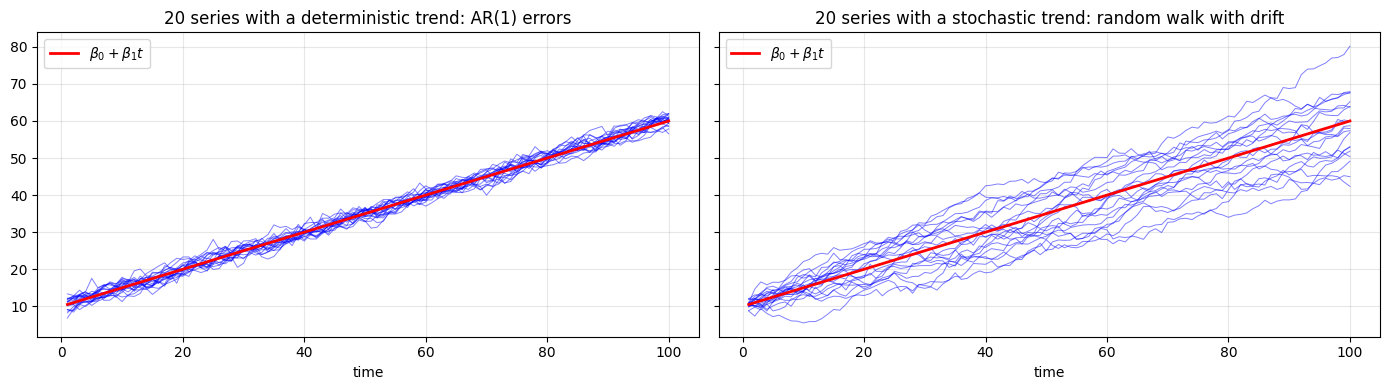

,t = 25,t = 50,t = 100
deterministic: across the 20 series,1.81,1.26,1.42
"deterministic: theory, 1/sqrt(1 - phi^2)",1.40,1.40,1.40
stochastic: across the 20 series,4.15,6.19,8.99
"stochastic: theory, sqrt(t)",5.00,7.07,10.00


In [4]:
b0, b1, phi = 10.0, 0.5, 0.7         # true intercept, slope, and AR(1) coefficient of the errors


def deterministic_trend(n, rng, burnin=200):
    "One series b0 + b1 t + eta_t, t = 1..n, with AR(1) errors eta_t = phi eta_{t-1} + eps_t."
    eps = rng.standard_normal(n + burnin)
    eta = np.zeros(n + burnin)
    for i in range(1, n + burnin):
        eta[i] = phi * eta[i - 1] + eps[i]
    return b0 + b1 * np.arange(1, n + 1) + eta[burnin:]


def stochastic_trend(n, rng):
    "One random walk with drift y_t = y_{t-1} + b1 + eps_t, t = 1..n, starting from y_0 = b0."
    return b0 + np.cumsum(b1 + rng.standard_normal(n))


n_sim, n_paths = 100, 20
t_sim = np.arange(1, n_sim + 1)
det_paths = np.array([deterministic_trend(n_sim, rng) for _ in range(n_paths)])
sto_paths = np.array([stochastic_trend(n_sim, rng) for _ in range(n_paths)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, paths, name in [(axes[0], det_paths, "deterministic trend: AR(1) errors"),
                        (axes[1], sto_paths, "stochastic trend: random walk with drift")]:
    ax.plot(t_sim, paths.T, color="blue", lw=0.7, alpha=0.5)
    ax.plot(t_sim, b0 + b1 * t_sim, color="red", lw=2, label=r"$\beta_0 + \beta_1 t$")
    ax.set(title=f"{n_paths} series with a {name}", xlabel="time")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

check = np.array([25, 50, 100])
pd.DataFrame({
    "deterministic: across the 20 series": det_paths[:, check - 1].std(axis=0, ddof=1),
    "deterministic: theory, 1/sqrt(1 - phi^2)": np.full(len(check), 1 / np.sqrt(1 - phi ** 2)),
    "stochastic: across the 20 series": sto_paths[:, check - 1].std(axis=0, ddof=1),
    "stochastic: theory, sqrt(t)": np.sqrt(check),
}, index=[f"t = {c}" for c in check]).T.round(2)

The table gives the standard deviation of $y_t$ across the series at three times.

- The **deterministic** series stay in a band of constant width around the line. The AR(1) errors have the constant standard deviation $\sigma/\sqrt{1 - \phi^2} = 1.40$, and the spread across the series scatters around this value without growing (each value is estimated from 20 series only).
- The **stochastic** series fan out and do not come back. The deviation from the line, $y_t - \beta_0 - \beta_1 t = \varepsilon_1 + \dots + \varepsilon_t$, is a sum of $t$ independent shocks, so its standard deviation grows like $\sqrt{t}$, from 5 at $t = 25$ to 10 at $t = 100$; across our 20 series, it grows from 4.2 to 9.0. Individual series spend long stretches above or below the line, and over such a stretch they seem to follow a different slope.

## Forecasts and prediction intervals

The same difference shows up in the forecasts. Suppose that the last observation is at time $T$.

- **Deterministic trend with AR(1) errors.** The forecast is the line plus the last deviation, which decays geometrically:
$$\hat y_{T+h} = \beta_0 + \beta_1 (T + h) + \phi^h\,\eta_T .$$
The forecast variance grows towards the variance of $\eta_t$, $\sigma^2 / (1 - \phi^2)$, and stops there: the prediction intervals have a maximum width.
- **Stochastic trend (random walk with drift).** The forecast starts from the last observation and adds the drift:
$$\hat y_{T+h} = y_T + \beta_1 h .$$
The forecast variance is $h\,\sigma^2$, which grows without bound. With ARMA errors the formulas are longer, but the variance still grows in proportion to $h$ at long horizons.

So the two models may agree on the slope and still disagree on where the forecasts start, and they always disagree on how uncertain the forecasts are at long horizons.

## Example: air passengers in Australia

The file `data/aus_airpassengers.csv` holds the total number of passengers, in millions, carried by Australian air carriers each year from 1970 to 2016. We index the years by their first day.

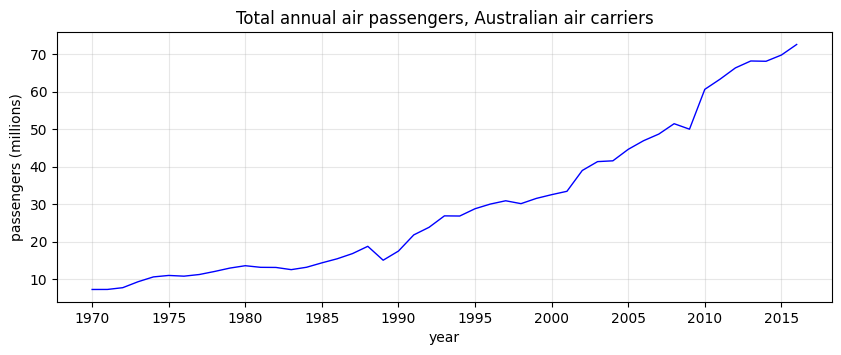

47 years, 1970-2016: from 7.3 to 72.6 million


In [5]:
air = pd.read_csv("data/aus_airpassengers.csv", usecols=["Year", "Passengers"])
air = air.set_index(pd.to_datetime(air["Year"].astype(str), format="%Y"))["Passengers"].asfreq("YS")
air.index.name = "year"

run_sequence_plot(air, title="Total annual air passengers, Australian air carriers",
                  xlabel="year", ylabel="passengers (millions)", figsize=(10, 3.5))
plt.show()
print(f"{len(air)} years, {air.index[0]:%Y}-{air.index[-1]:%Y}: from {air.iloc[0]:.1f} to {air.iloc[-1]:.1f} million")

The number of passengers grew roughly tenfold over 47 years, with a sharp dip in 1989, the year of the industrial dispute we saw in the Ansett data of Chapter 3, and with faster growth after 2000. Both trend models regress $y_t$ on $t = 1, 2, \dots, 47$, which we pass as a one-column `exog`. For each one we choose the ARMA order of the errors with `select_arma`, comparing AICc values only between models with the same $d$ (Chapter 12).

In [6]:
t_air = pd.DataFrame({"t": np.arange(1, len(air) + 1)}, index=air.index)    # the trend as a predictor

grid_det = select_arma(air, exog=t_air, d=0, trend="c")      # deterministic trend: ARMA errors
grid_sto = select_arma(air, exog=t_air, d=1, trend="n")      # stochastic trend: ARIMA(p, 1, q) errors
pd.concat({"deterministic trend (d = 0)": grid_det.head(4),
           "stochastic trend (d = 1)": grid_sto.head(4)}, axis=1).round(2)

deterministic trend (d = 0)                          \
                        order     AIC    AICc     BIC   
0                   (1, 0, 0)  209.77  210.72  217.17   
1                   (2, 0, 2)  208.38  211.25  221.33   
2                   (2, 0, 0)  211.76  213.23  221.01   
3                   (1, 0, 1)  211.76  213.23  221.01   

  stochastic trend (d = 1)                          
                     order     AIC    AICc     BIC  
0                (0, 1, 0)  200.31  200.59  203.97  
1                (1, 1, 0)  202.29  202.86  207.77  
2                (0, 1, 1)  202.29  202.86  207.78  
3                (1, 1, 1)  203.35  204.32  210.66

AICc selects AR(1) errors for the deterministic trend, and ARIMA(0,1,0) errors, a plain random walk, for the stochastic one. With only 47 observations, the small-sample correction matters: AIC alone would have preferred ARMA(2,2) errors for the deterministic trend, with three more coefficients, while AICc puts that model second. We fit the two selected models.

In [7]:
fit_det = ARIMA(air, exog=t_air, order=(1, 0, 0), trend="c").fit()
fit_sto = ARIMA(air, exog=t_air, order=(0, 1, 0)).fit()

pd.DataFrame({"deterministic trend": fit_det.params, "stochastic trend": fit_sto.params}
             ).reindex(["const", "t", "ar.L1", "sigma2"]).round(3)

,deterministic trend,stochastic trend
const,0.902,NaN
t,1.415,1.419
ar.L1,0.956,NaN
sigma2,4.066,4.178


The deterministic trend model is

$$y_t = 0.902 + 1.415\,t + \eta_t, \qquad \eta_t = 0.956\,\eta_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \mathrm{NID}(0,\ 4.07),$$

and the stochastic trend model is $y_t - y_{t-1} = 1.419 + \varepsilon_t$, or equivalently

$$y_t = y_0 + 1.419\,t + \eta_t, \qquad \eta_t = \eta_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \mathrm{NID}(0,\ 4.18),$$

where NID stands for normally and independently distributed. Both models estimate the growth at 1.42 million passengers per year. The stochastic model has no intercept: $y_0$ is not estimated, since the forecasts start from the last observation anyway.

**The drift is set by the endpoints.** For a random walk with drift, the estimated drift is the mean of the differences, which telescopes:

$$\hat\beta_1 = \frac{1}{T-1}\sum_{t=2}^{T}(y_t - y_{t-1}) = \frac{y_T - y_1}{T - 1} .$$

Only the first and the last observations matter.

In [8]:
print(f"drift of the stochastic trend model: {fit_sto.params['t']:.4f}")
print(f"(y_T - y_1) / (T - 1)              : {(air.iloc[-1] - air.iloc[0]) / (len(air) - 1):.4f}")

drift of the stochastic trend model: 1.4191
(y_T - y_1) / (T - 1)              : 1.4191


### Regression residuals and innovation residuals

For the deterministic trend model, $\hat\eta_t$ is the deviation from the fitted line, and $\hat\varepsilon_t$ what is left after the AR(1) model has predicted $\hat\eta_t$ from $\hat\eta_{t-1}$.

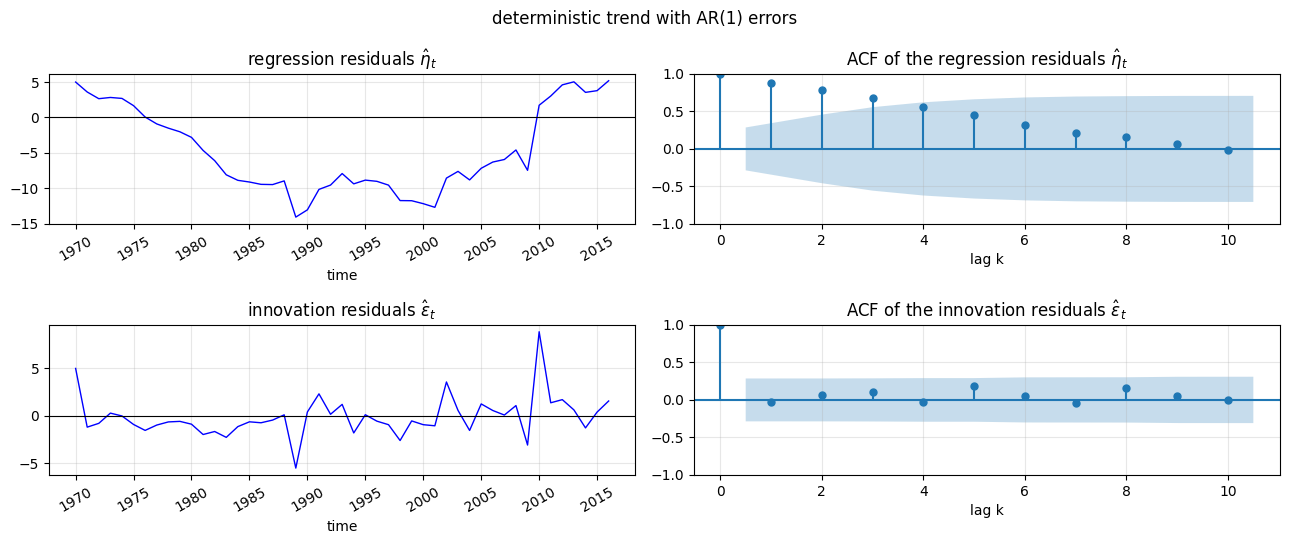

Ljung-Box, regression residuals (lag 10, model_df = 0): Q = 133.20, p = 1.04e-23
Ljung-Box, innovation residuals (lag 10, model_df = 1): Q = 4.72, p = 0.858


In [9]:
residual_check(fit_det, air, t_air, lags=10, title="deterministic trend with AR(1) errors")

The regression residuals stay on one side of the line for decades: above it until the mid-1970s and after 2010, below it from 1977 to 2009. Their ACF decays slowly, and the Ljung-Box test rejects white noise by a wide margin; OLS would be the wrong tool here. The innovation residuals pass the test: the AR(1) model has absorbed the autocorrelation. The largest innovations are the drop of 1989, the industrial dispute, and the jump of 2010, when the number of passengers rose by 10.6 million in a single year.

For the stochastic trend model, the regression residuals $\hat\eta_t = y_t - 1.419\,t$ are a random walk by construction, and the innovation residuals are the differences minus the drift. We only test the latter.

In [10]:
eps_sto = fit_sto.resid.iloc[fit_sto.loglikelihood_burn:]      # the first residual is the initialization
lb = acorr_ljungbox(eps_sto, lags=[10], model_df=0)
print(f"Ljung-Box, innovation residuals of the stochastic trend model (lag 10): "
      f"Q = {lb['lb_stat'].iloc[0]:.2f}, p = {lb['lb_pvalue'].iloc[0]:.3g}")

Ljung-Box, innovation residuals of the stochastic trend model (lag 10): Q = 6.66, p = 0.757


Both models pass their residual checks, so the residuals cannot tell us which trend is right. Look again at the regression residuals of the deterministic model: deviations from a line that persist with $\hat\phi_1 = 0.956$, one of them for 33 years. The stochastic model describes almost the same deviations as a random walk, $\phi_1 = 1$. From 47 observations, 0.956 and 1 are hard to tell apart, and the two models fit the past almost equally well.

### Forecasts

They do not forecast equally. We forecast 20 years ahead; the future values of the predictor are simply $t = 48, \dots, 67$.

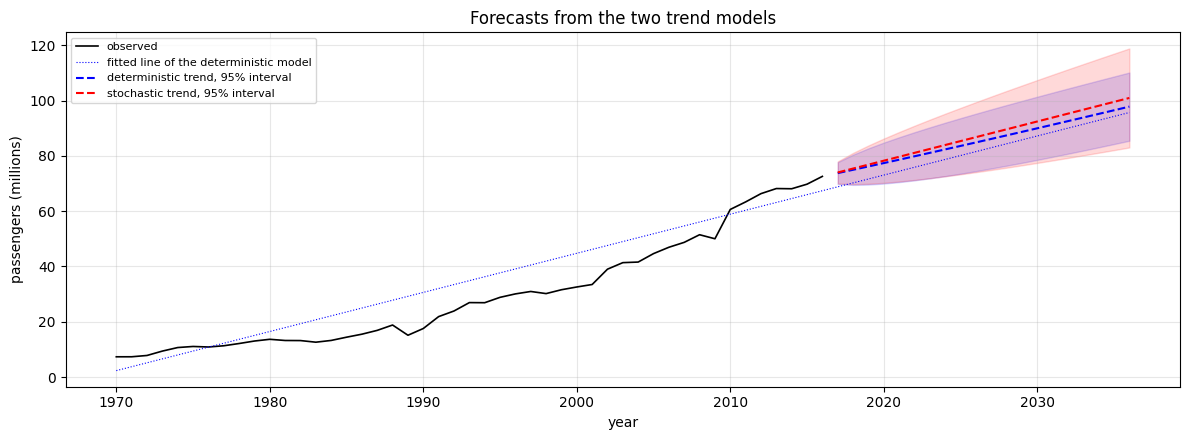

h =  1: forecasts   73.8 and   74.0,   95% interval widths   7.9 and   8.0
h =  5: forecasts   78.6 and   79.7,   95% interval widths  16.2 and  17.9
h = 10: forecasts   84.9 and   86.8,   95% interval widths  20.8 and  25.3
h = 20: forecasts   97.8 and  101.0,   95% interval widths  24.7 and  35.8

last deviation from the line: eta_T = 5.19;  maximum width of the deterministic interval: 27.1


In [11]:
H = 20
t_future = pd.DataFrame({"t": np.arange(len(air) + 1, len(air) + H + 1)},
                        index=pd.date_range(air.index[-1] + pd.DateOffset(years=1), periods=H, freq="YS"))

_, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(air, color="black", lw=1.2, label="observed")
all_t = pd.concat([t_air, t_future])
ax.plot(all_t.index, fit_det.params["const"] + fit_det.params["t"] * all_t["t"], color="blue", lw=0.8, ls=":",
        label="fitted line of the deterministic model")
pred_det = forecast_with_interval(ax, fit_det, H, t_future.index, exog=t_future, color="blue",
                                  label="deterministic trend, 95% interval")
pred_sto = forecast_with_interval(ax, fit_sto, H, t_future.index, exog=t_future, color="red",
                                  label="stochastic trend, 95% interval")
ax.set(title="Forecasts from the two trend models", xlabel="year", ylabel="passengers (millions)")
ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

widths = {name: np.diff(np.asarray(fit.get_forecast(H, exog=t_future).conf_int(alpha=0.05)), axis=1).ravel()
          for name, fit in [("deterministic", fit_det), ("stochastic", fit_sto)]}
for h in [1, 5, 10, 20]:
    print(f"h = {h:2d}: forecasts {pred_det[h - 1]:6.1f} and {pred_sto[h - 1]:6.1f},   "
          f"95% interval widths {widths['deterministic'][h - 1]:5.1f} and {widths['stochastic'][h - 1]:5.1f}")
eta_T = regression_residuals(fit_det, air, t_air).iloc[-1]
print(f"\nlast deviation from the line: eta_T = {eta_T:.2f};  "
      f"maximum width of the deterministic interval: {2 * 1.96 * np.sqrt(fit_det.params['sigma2'] / (1 - fit_det.params['ar.L1'] ** 2)):.1f}")

- The point forecasts are close. In 2016 the series was 5.2 million above the fitted line, and the deterministic forecast keeps $0.956^h$ of that gap: it reverts to the line, but slowly, so after 20 years it is still 2 million above the line and 3 million below the stochastic forecast.
- The prediction intervals are not close. Both start at a width of 8 million. The deterministic interval widens towards its maximum width, $2 \times 1.96 \times \hat\sigma / \sqrt{1 - \hat\phi^2} \approx 27$ million, and is 25 million wide at $h = 20$. The stochastic interval keeps widening like $\sqrt{h}$, to 36 million at $h = 20$.

### Which model?

The two models report AIC values of 209.8 and 200.3. It is tempting to pick the stochastic trend, but the comparison is not allowed: the likelihood of a model with $d = 1$ is computed on the 46 differences, not on the 47 levels (Chapter 12). We need other evidence.

**Unit-root tests.** The ADF test of Chapter 5, with `regression="ct"`, includes a trend in its test equation. Its null hypothesis is a unit root (a stochastic trend), and its alternative is stationarity around a linear trend (a deterministic trend). The KPSS test with `regression="ct"` has the hypotheses the other way round: its null is stationarity around a linear trend.

In [12]:
adf_stat, adf_p = adfuller(air, regression="ct")[:2]
kpss_stat, kpss_p, _, kpss_crit = kpss(air, regression="ct", nlags="auto")

print(f"ADF  (H0: unit root)               : statistic = {adf_stat:6.3f}, p = {adf_p:.3f}")
print(f"KPSS (H0: stationary around a line): statistic = {kpss_stat:6.3f}, "
      f"critical values 5%: {kpss_crit['5%']:.3f}, 1%: {kpss_crit['1%']:.3f}  (p < {kpss_p:.2f})")

ADF  (H0: unit root)               : statistic = -0.927, p = 0.953
KPSS (H0: stationary around a line): statistic =  0.253, critical values 5%: 0.146, 1%: 0.216  (p < 0.01)


The ADF test does not come close to rejecting a unit root ($p = 0.95$), and the KPSS statistic exceeds even its 1% critical value: KPSS rejects stationarity around a line. The two tests agree on a stochastic trend.

The usual caveat applies. With 47 observations and $\hat\phi_1 = 0.956$, the tests have little power, and they are evidence rather than proof. The more useful question for forecasting is what each model would have predicted. We check that on held-out data.

### A check on held-out data

We stop the data at three forecast origins, 1996, 2001 and 2006, fit both models with the orders selected above, and forecast up to 2016: 20, 15 and 10 years ahead. For each origin, the table gives the average growth per year before and after the origin, the test MSE, and the share of test years inside the 95% prediction interval.

In [13]:
rows, preds = [], {}
for origin in [1996, 2001, 2006]:
    train, test = air[:str(origin)], air[str(origin + 1):]
    t_train, t_test = t_air[:str(origin)], t_air[str(origin + 1):]
    row = {"origin": origin, "h": len(test),
           "growth before": (train.iloc[-1] - train.iloc[0]) / (len(train) - 1),
           "growth after": (test.iloc[-1] - train.iloc[-1]) / len(test)}
    for name, order, trend in [("deterministic", (1, 0, 0), "c"), ("stochastic", (0, 1, 0), "n")]:
        fc = ARIMA(train, exog=t_train, order=order, trend=trend).fit().get_forecast(len(test), exog=t_test)
        ci = np.asarray(fc.conf_int(alpha=0.05))
        inside = (test.to_numpy() >= ci[:, 0]) & (test.to_numpy() <= ci[:, 1])
        row[f"MSE {name}"] = mse(test, fc.predicted_mean)
        row[f"coverage {name}"] = inside.mean()
        preds[origin, name] = (np.asarray(fc.predicted_mean), ci)
    rows.append(row)
holdout = pd.DataFrame(rows).set_index("origin")
holdout.round(2)

,h,growth before,growth after,MSE deterministic,coverage deterministic,MSE stochastic,coverage stochastic
origin,,,,,,,
1996,20,0.88,2.13,264.26,0.25,194.27,0.6
2001,15,0.84,2.61,330.33,0.00,296.66,0.0
2006,10,1.10,2.56,142.84,0.30,109.22,0.3


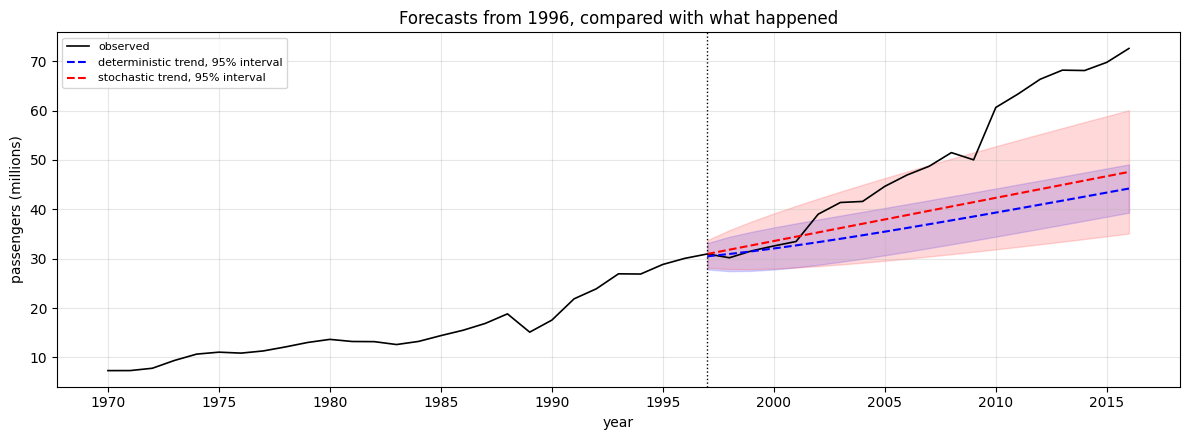

In [14]:
origin = 1996
test = air[str(origin + 1):]
_, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(air, color="black", lw=1.2, label="observed")
for name, color in [("deterministic", "blue"), ("stochastic", "red")]:
    pred, ci = preds[origin, name]
    ax.plot(test.index, pred, color=color, ls="--", lw=1.5, label=f"{name} trend, 95% interval")
    ax.fill_between(test.index, ci[:, 0], ci[:, 1], color=color, alpha=0.15)
ax.axvline(test.index[0], color="black", ls=":", lw=1)
ax.set(title=f"Forecasts from {origin}, compared with what happened", xlabel="year",
       ylabel="passengers (millions)")
ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

- **Neither model saw the faster growth coming.** Before 1996 the series grew by 0.88 million passengers per year; after 1996 by 2.13. Both models extrapolate the historical average slope, so both forecasts fall well below the outcome, from every origin.
- **The stochastic trend did better every time.** Its MSE is the lower at all three origins, and from 1996 its interval contains 60% of the test years, against 25% for the deterministic trend. Its wider intervals were not a weakness but an honest statement of how far a trend can drift in 20 years.
- **Neither interval reaches 95% coverage.** Prediction intervals assume that the model is right. A change of slope is outside both models, and from 2001 no test year falls inside either interval.

This is the forecasting argument for stochastic trends. A deterministic trend assumes that the slope never changes and that every deviation from the line will be undone. A stochastic trend only assumes that the average past growth is the best guess for the future, and it lets the uncertainty grow with the horizon. It is therefore the safer choice, especially for long horizons.

## Which mistake costs more?

The held-out check covers one series, and the three test periods overlap. A simulation answers the general question: when we fit the wrong trend model, how wrong are the forecasts and the intervals? We generate 100 series of each kind, with the same parameters as above and 120 points each. For each series, we fit both trend models to the first 100 points, with the true error orders, forecast the last 20, and record the coverage of the 95% intervals, their width at $h = 20$, and the MSE.

In [15]:
n_fit, H_sim, R = 100, 20, 100
t_train, t_test = np.arange(1, n_fit + 1), np.arange(n_fit + 1, n_fit + H_sim + 1)

start = time.perf_counter()
rows = []
for data, simulate in [("deterministic", deterministic_trend), ("stochastic", stochastic_trend)]:
    for _ in range(R):
        y = simulate(n_fit + H_sim, rng)
        train, test = y[:n_fit], y[n_fit:]
        for model, order, trend in [("deterministic", (1, 0, 0), "c"), ("stochastic", (0, 1, 0), "n")]:
            fit = ARIMA(train, exog=t_train, order=order, trend=trend).fit()
            fc = fit.get_forecast(H_sim, exog=t_test)
            ci = fc.conf_int(alpha=0.05)
            inside = (test >= ci[:, 0]) & (test <= ci[:, 1])
            rows.append({"data": data, "model": model,
                         "coverage, all 20 steps": inside.mean(), "coverage at h = 20": inside[-1],
                         "interval width at h = 20": ci[-1, 1] - ci[-1, 0],
                         "MSE": mse(test, fc.predicted_mean),
                         "phi_1": fit.params[2] if model == "deterministic" else np.nan})
print(f"time required: {time.perf_counter() - start:.0f} s for {len(rows)} fits")

simulation = pd.DataFrame(rows).groupby(["data", "model"]).mean()
print("mean estimate of phi_1, deterministic model fitted to stochastic trends: "
      f"{simulation.loc[('stochastic', 'deterministic'), 'phi_1']:.3f}\n")
simulation.drop(columns="phi_1").round(2)

time required: 14 s for 400 fits
mean estimate of phi_1, deterministic model fitted to stochastic trends: 0.913


coverage, all 20 steps  coverage at h = 20  \
data          model                                                       
deterministic deterministic                    0.91                0.84   
              stochastic                       0.99                1.00   
stochastic    deterministic                    0.78                0.61   
              stochastic                       0.93                0.92   

                             interval width at h = 20    MSE  
data          model                                           
deterministic deterministic                      5.22   2.24  
              stochastic                        19.08   3.39  
stochastic    deterministic                      9.78  14.96  
              stochastic                        17.41  12.33

Read the table by blocks of two rows: the data were generated with one kind of trend, and each row is one of the two models fitted to them.

- **The right model** covers 91% to 93% of the test points with its nominal 95% intervals. The shortfall is the price of estimating the parameters: the intervals treat the estimates as the true values.
- **A deterministic trend fitted to a stochastic trend** is overconfident. Its intervals cover 78% of the test points, and only 61% at $h = 20$, where they are little more than half as wide as they should be (9.8 against 17.4). Nothing in the fitted model gives this away: the AR coefficient comes out at 0.91 on average, a perfectly ordinary stationary value, like the 0.956 of the air passengers. Its MSE is about 20% larger than that of the right model.
- **A stochastic trend fitted to a deterministic trend** is too cautious. Its intervals cover almost everything, and at $h = 20$ they are more than three times wider than necessary. The point forecasts suffer too: they start from the last observation instead of the line, and the MSE is about 50% larger.

Both mistakes cost something, but not the same thing. The stochastic mistake gives intervals that are visibly too wide; the deterministic mistake gives intervals that are too narrow and look perfectly reasonable. Unless there is a good reason to believe that the slope is fixed, such as a physical law or a contract, the stochastic trend is the safer default for long horizons.

---

# Summary

**Regression with ARIMA errors**: $\ y_t = \beta_0 + \beta_1 x_{1,t} + \dots + \beta_k x_{k,t} + \eta_t$, with $\eta_t$ an ARIMA process and white-noise innovations $\varepsilon_t$.

- Fit with `ARIMA(y, exog=X, order=(p, d, q), trend=...)` and forecast with `get_forecast(h, exog=X_future)`. With $d \ge 1$, the whole regression is differenced and the intercept drops out.
- Two residual series: the **regression residuals** $\hat\eta_t$ may be autocorrelated; the **innovation residuals** $\hat\varepsilon_t$ (`fit.resid`) must look like white noise.
- OLS on autocorrelated errors gives inefficient estimates, wrong standard errors and misleading information criteria.

**Deterministic vs stochastic trend**

| | Deterministic trend | Stochastic trend |
|---|---|---|
| Model | $y_t = \beta_0 + \beta_1 t + \eta_t$, $\eta_t$ ARMA | $y_t = \beta_0 + \beta_1 t + \eta_t$, $\eta_t$ ARIMA with $d = 1$ |
| Equivalent form | line plus stationary deviations | $y_t = y_{t-1} + \beta_1 + \eta'_t$: random walk with drift and ARMA errors |
| `statsmodels` | `ARIMA(y, exog=t, order=(p, 0, q), trend="c")` | `ARIMA(y, exog=t, order=(p, 1, q))` |
| A shock is | temporary: the series returns to the line | permanent: the series never returns |
| Point forecast | reverts to the line at rate $\phi^h$ | starts from $y_T$, adds $\beta_1$ per step |
| Interval width | bounded by $2 \times 1.96\,\sigma_\eta$ | grows like $\sqrt{h}$ |
| Slope estimate | from all observations | $(y_T - y_1)/(T - 1)$, the endpoints only |
| If wrongly chosen | intervals far too narrow | intervals too wide, larger MSE |

**Choosing between them**: AIC and AICc cannot compare models with different $d$. Use ADF and KPSS with `regression="ct"`, keeping their low power in mind, and forecasts on held-out data. For long horizons, prefer the stochastic trend.
